In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import numpy as np

# Determine where the CSV files are relative to this notebook
clean_dir = "."  # Default to current directory
found_csvs = False

# Check current directory first
if any(f.endswith(".csv") for f in os.listdir(".")):
    clean_dir = "."
    found_csvs = True
else:
    # Check common relative paths
    potential_paths = [
        "Drone Logs/Clean CSVs",
        "Data/Drone Logs/Clean CSVs",
        "../Drone Logs/Clean CSVs" # In case notebook is in a sibling folder
    ]
    for p in potential_paths:
        if os.path.exists(p) and any(f.endswith(".csv") for f in os.listdir(p)):
            clean_dir = p
            found_csvs = True
            break

if not found_csvs:
    print("Could not find directory containing CSV files.")
else:
    print(f"Reading flights from: {clean_dir}")

# Data storage
flight_summaries = []
sample_flight_data = None
longest_duration = 0

print("Reading and summarizing flight files...")

if found_csvs:
    for filename in os.listdir(clean_dir):
        if filename.endswith(".csv"):
            try:
                file_path = os.path.join(clean_dir, filename)
                df = pd.read_csv(file_path, low_memory=False)
                
                # Metrics to extract
                metrics = {'Filename': filename}
                
                # 1. Duration
                if 'OSD.flyTime' in df.columns:
                    duration = df['OSD.flyTime'].max() - df['OSD.flyTime'].min()
                    metrics['Duration (s)'] = duration
                    
                    # Keep the longest flight as a sample for detailed plotting
                    if duration > longest_duration:
                        longest_duration = duration
                        sample_flight_data = df.copy()
                        sample_flight_name = filename
                
                # 2. Altitude
                if 'OSD.height' in df.columns:
                    metrics['Max Height (m)'] = df['OSD.height'].max()
                elif 'OSD.altitude' in df.columns:
                     metrics['Max Height (m)'] = df['OSD.altitude'].max()

                # 3. Speed (Horizontal)
                if 'OSD.xSpeed' in df.columns and 'OSD.ySpeed' in df.columns:
                    # Calculate horizontal speed magnitude
                    df['horizontal_speed'] = np.sqrt(df['OSD.xSpeed']**2 + df['OSD.ySpeed']**2)
                    metrics['Max Horizontal Speed (m/s)'] = df['horizontal_speed'].max()
                    metrics['Avg Horizontal Speed (m/s)'] = df['horizontal_speed'].mean()
                
                # 4. Battery Consumption
                if 'BATTERY.chargeLevel' in df.columns:
                    # Use max - min to ensure positive consumption value
                    metrics['Battery Consumed (%)'] = df['BATTERY.chargeLevel'].max() - df['BATTERY.chargeLevel'].min()
                    metrics['Min Battery Level (%)'] = df['BATTERY.chargeLevel'].min()
                
                # 5. Satellites
                if 'OSD.gpsNum' in df.columns:
                    metrics['Avg Satellite Count'] = df['OSD.gpsNum'].mean()
                
                flight_summaries.append(metrics)
                
            except Exception as e:
                print(f"Error reading {filename}: {e}")
    
    print(f"Processed {len(flight_summaries)} flights.")
    summary_df = pd.DataFrame(flight_summaries)


Reading flights from: .
Reading and summarizing flight files...
Processed 729 flights.


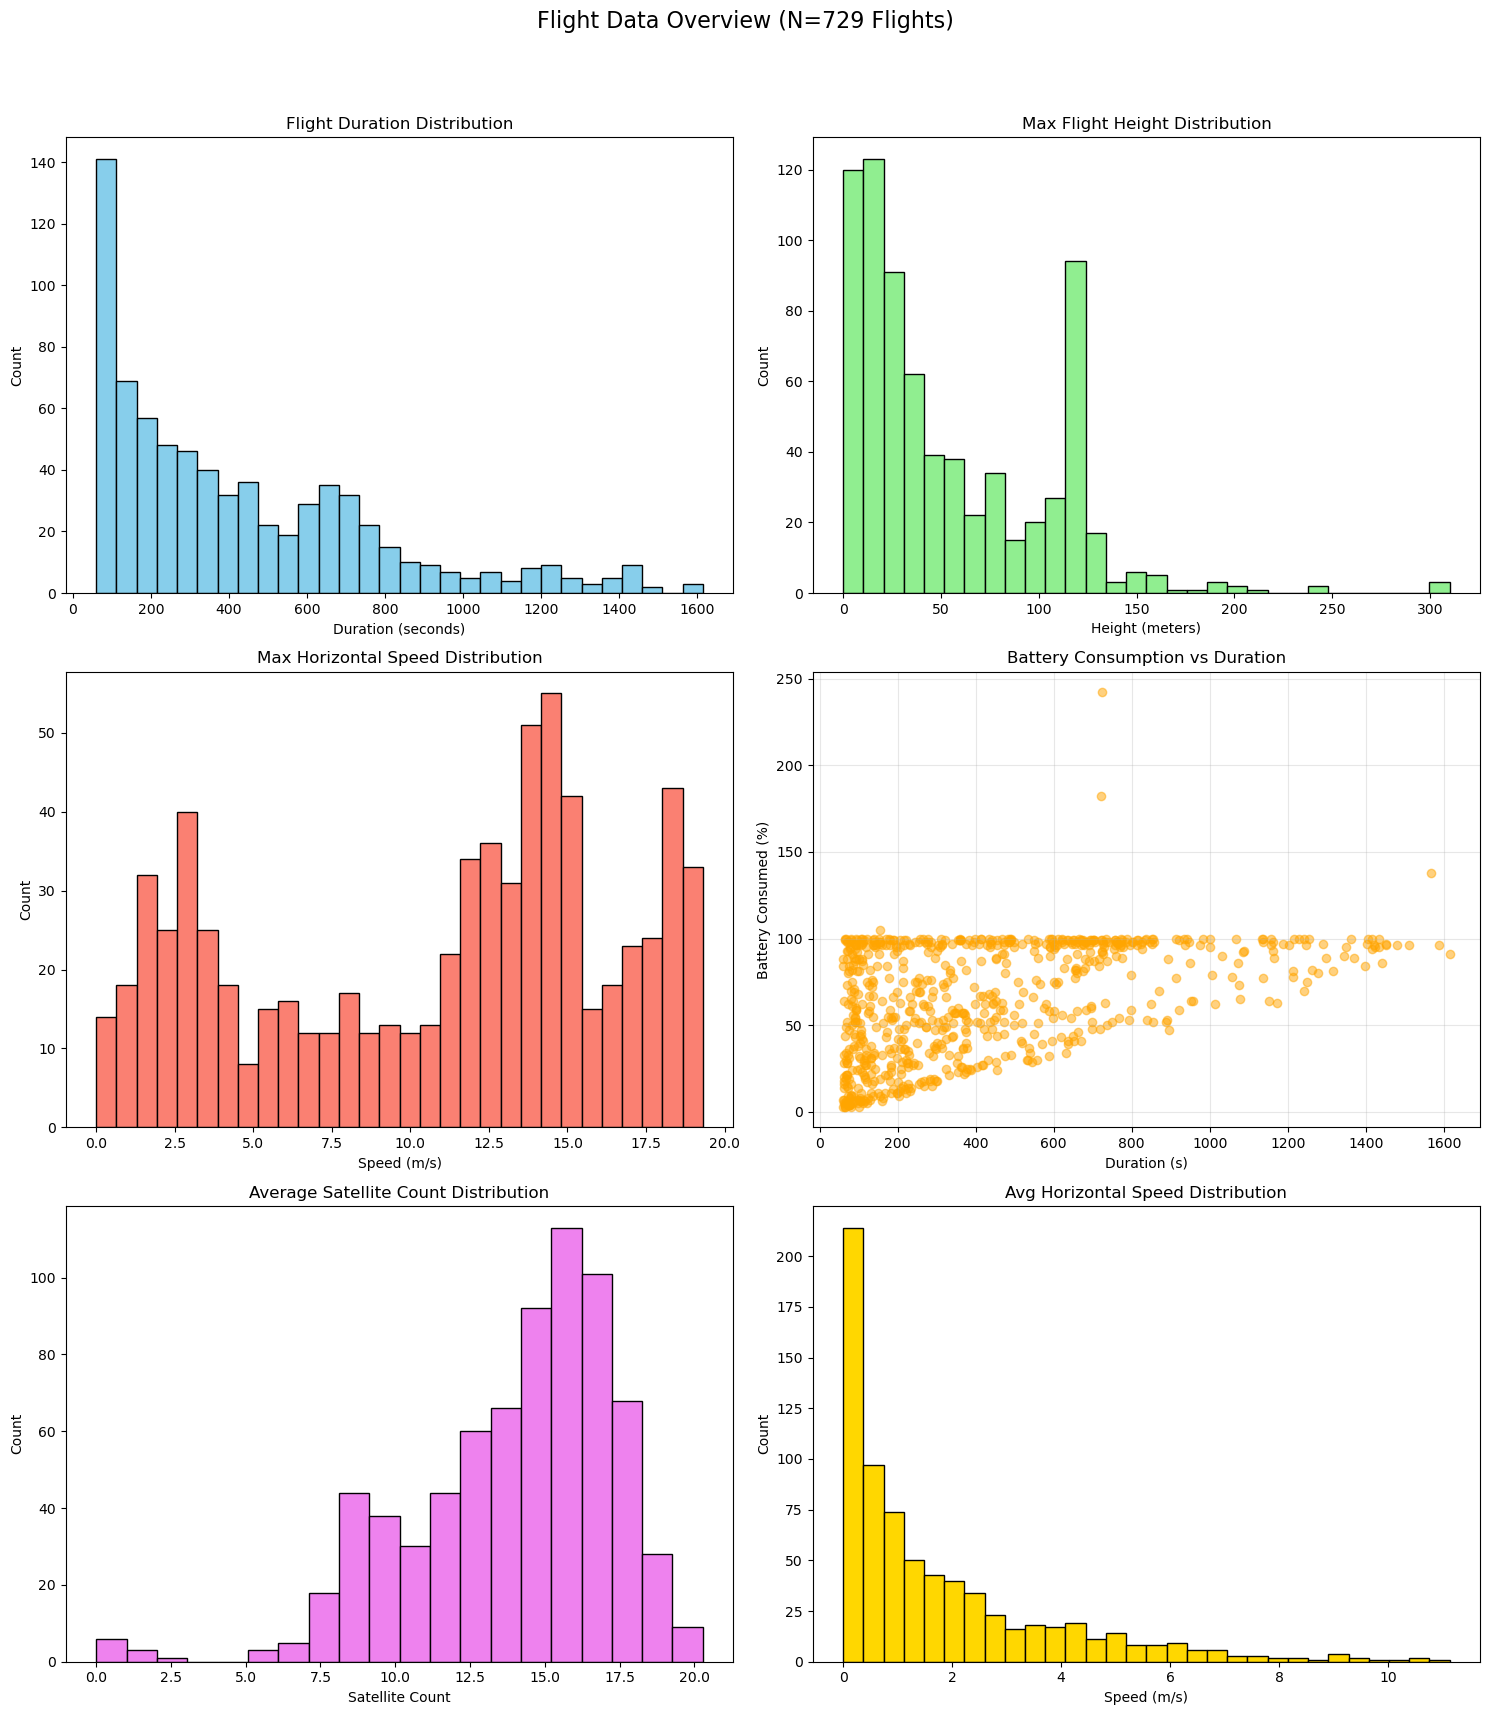

In [2]:
if not summary_df.empty:
    # Set up a generic plotting style
    plt.style.use('default') # Reset to default just in case
    fig, axes = plt.subplots(3, 2, figsize=(15, 18))
    fig.suptitle(f'Flight Data Overview (N={len(summary_df)} Flights)', fontsize=16)

    # 1. Duration Distribution
    if 'Duration (s)' in summary_df.columns:
        axes[0, 0].hist(summary_df['Duration (s)'].dropna(), bins=30, color='skyblue', edgecolor='black')
        axes[0, 0].set_title('Flight Duration Distribution')
        axes[0, 0].set_xlabel('Duration (seconds)')
        axes[0, 0].set_ylabel('Count')

    # 2. Max Height Distribution
    if 'Max Height (m)' in summary_df.columns:
        axes[0, 1].hist(summary_df['Max Height (m)'].dropna(), bins=30, color='lightgreen', edgecolor='black')
        axes[0, 1].set_title('Max Flight Height Distribution')
        axes[0, 1].set_xlabel('Height (meters)')
        axes[0, 1].set_ylabel('Count')

    # 3. Max Speed Distribution
    if 'Max Horizontal Speed (m/s)' in summary_df.columns:
        axes[1, 0].hist(summary_df['Max Horizontal Speed (m/s)'].dropna(), bins=30, color='salmon', edgecolor='black')
        axes[1, 0].set_title('Max Horizontal Speed Distribution')
        axes[1, 0].set_xlabel('Speed (m/s)')
        axes[1, 0].set_ylabel('Count')

    # 4. Battery vs Duration
    if 'Duration (s)' in summary_df.columns and 'Battery Consumed (%)' in summary_df.columns:
        axes[1, 1].scatter(summary_df['Duration (s)'], summary_df['Battery Consumed (%)'], alpha=0.5, color='orange')
        axes[1, 1].set_title('Battery Consumption vs Duration')
        axes[1, 1].set_xlabel('Duration (s)')
        axes[1, 1].set_ylabel('Battery Consumed (%)')
        axes[1, 1].grid(True, alpha=0.3)

    # 5. Satellite Count
    if 'Avg Satellite Count' in summary_df.columns:
        axes[2, 0].hist(summary_df['Avg Satellite Count'].dropna(), bins=20, color='violet', edgecolor='black')
        axes[2, 0].set_title('Average Satellite Count Distribution')
        axes[2, 0].set_xlabel('Satellite Count')
        axes[2, 0].set_ylabel('Count')
    
    # 6. Average Horizontal Speed (NEW)
    if 'Avg Horizontal Speed (m/s)' in summary_df.columns:
        axes[2, 1].hist(summary_df['Avg Horizontal Speed (m/s)'].dropna(), bins=30, color='gold', edgecolor='black')
        axes[2, 1].set_title('Avg Horizontal Speed Distribution')
        axes[2, 1].set_xlabel('Speed (m/s)')
        axes[2, 1].set_ylabel('Count')
    else:
        axes[2, 1].axis('off')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()
else:
    print("No summary data available to plot.")

In [3]:
# Outlier Analysis - Battery
if not summary_df.empty and 'Battery Consumed (%)' in summary_df.columns:
    # Definition of outlier: Consumption <= 0 or > 100
    outliers = summary_df[
        (summary_df['Battery Consumed (%)'] <= 0) | 
        (summary_df['Battery Consumed (%)'] > 100)
    ]
    
    if not outliers.empty:
        print(f"Found {len(outliers)} flights with suspicious battery consumption:")
        print(outliers[['Filename', 'Duration (s)', 'Battery Consumed (%)', 'Max Height (m)']])
    else:
        print("No obvious battery outliers (<= 0% or > 100%) found.")
        
    # Check for low consumption on long flights
    low_drain_long = summary_df[
        (summary_df['Duration (s)'] > 60) & 
        (summary_df['Battery Consumed (%)'] < 2)
    ]
    if not low_drain_long.empty:
        print(f"\nFound {len(low_drain_long)} long flights (>60s) with <2% battery drain (Potential sensor freeze):")
        print(low_drain_long[['Filename', 'Duration (s)', 'Battery Consumed (%)']])
else:
    print("Battery data not available for analysis.")

Found 4 flights with suspicious battery consumption:
                                      Filename  Duration (s)  \
367  DJIFlightRecord_2019-08-31_[13-43-14].csv         720.3   
382  DJIFlightRecord_2019-09-22_[20-14-19].csv         153.7   
429  DJIFlightRecord_2020-06-18_[19-35-08].csv        1567.8   
566  DJIFlightRecord_2019-04-16_[20-07-38].csv         722.9   

     Battery Consumed (%)  Max Height (m)  
367                   182           123.3  
382                   105             6.1  
429                   138            82.8  
566                   242           121.3  
